# ۰۳ - تحلیل سفارش‌ها و روند کسب‌وکار

پاسخ به سؤال‌های ۵.۱ تا ۵.۴ صورت‌مسئله: وضعیت سفارش‌ها، روند ماهانه، الگوی هفتگی و ماه‌های پرتراکنش.

## ۲. سؤال‌های کسب‌وکاری

1. تعداد کل سفارش‌ها و سهم هر وضعیت چقدر است؟
2. روند ماهانه تعداد سفارش‌ها چگونه است و کدام ماه بیشترین سفارش را دارد؟
3. آیا رشد پایدار است یا فصلی؟
4. مشتریان در چه روزهایی بیشتر سفارش می‌دهند؟
5. پنج ماه پرتراکنش کدام‌اند؟

## ۱. عنوان و هدف

پاسخ به سؤال‌های ۵.۱ تا ۵.۴ صورت‌مسئله: وضعیت سفارش‌ها، روند ماهانه، الگوی هفتگی و ماه‌های پرتراکنش.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from olist_analysis import metrics as M
from olist_analysis.config import FIGURES_DIR, REPORTS_DIR, TABLES_DIR
from olist_analysis.font_utils import persian_available
from olist_analysis.features import load_dataset
from olist_analysis.pipeline import load_headline

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

ds = load_dataset()
headline = load_headline()
print("Persian font registered for charts:", persian_available())
print(f"orders={len(ds.orders):,}  items={len(ds.items):,}  "
      f"delivered={len(ds.delivered):,}  reviewed={len(ds.reviews_per_order):,}")


Persian font registered for charts: True
orders=99,441  items=112,650  delivered=96,470  reviewed=98,673


## ۴. روش محاسبه

ماه‌ها با `purchase_ym` گروه‌بندی می‌شوند. برای تحلیل روند فقط ماه‌های پیوسته ۲۰۱۷-۰۱ تا ۲۰۱۸-۰۸ (۹۹٬۰۹۲ سفارش) استفاده می‌شود؛ سال ۲۰۱۶ سه ماه پراکنده ناقص و دو ماه پایانی ۲۰۱۸ ناقص هستند.

## ۶. تحلیل عددی

### ۵.۱ وضعیت سفارش‌ها

In [2]:
display(M.order_status_summary(ds))

,order_status,n_orders,pct_orders,is_delivered
0,delivered,96478,97.0203,True
1,shipped,1107,1.1132,False
2,canceled,625,0.6285,False
3,unavailable,609,0.6124,False
4,invoiced,314,0.3158,False
5,processing,301,0.3027,False
6,created,5,0.0050,False
7,approved,2,0.0020,False


### ۵.۲ روند ماهانه

In [3]:
display(M.monthly_orders(ds))

,purchase_ym,n_orders,n_delivered,in_core_window,order_month,n_orders_rolling3,pct_of_total
0,2016-09,4,1,False,2016-09-01,4.00,0.0040
1,2016-10,324,265,False,2016-10-01,164.00,0.3258
2,2016-12,1,1,False,2016-12-01,109.67,0.0010
3,2017-01,800,750,True,2017-01-01,375.00,0.8045
4,2017-02,1780,1653,True,2017-02-01,860.33,1.7900
5,2017-03,2682,2546,True,2017-03-01,1754.00,2.6971
6,2017-04,2404,2303,True,2017-04-01,2288.67,2.4175
7,2017-05,3700,3546,True,2017-05-01,2928.67,3.7208
8,2017-06,3245,3135,True,2017-06-01,3116.33,3.2632
9,2017-07,4026,3872,True,2017-07-01,3657.00,4.0486


In [4]:
display(M.year_month_matrix(ds))

,purchase_year,month_01,month_02,month_03,month_04,month_05,month_06,month_07,month_08,month_09,month_10,month_11,month_12,total,avg_per_active_month
0,2016,0,0,0,0,0,0,0,0,4,324,0,1,329,109.7
1,2017,800,1780,2682,2404,3700,3245,4026,4331,4285,4631,7544,5673,45101,3758.4
2,2018,7269,6728,7211,6939,6873,6167,6292,6512,16,4,0,0,54011,5401.1


### ۵.۳ الگوی هفتگی

In [5]:
display(M.weekday_orders(ds))

,weekday,n_orders,pct_orders,avg_orders_per_day
0,Monday,16196,16.2870,174.2
1,Tuesday,15963,16.0527,175.4
2,Wednesday,15552,15.6394,170.9
3,Thursday,14761,14.8440,160.4
4,Friday,14122,14.2014,158.7
5,Saturday,10887,10.9482,122.3
6,Sunday,11960,12.0272,134.4


### ۵.۴ پنج ماه پرتراکنش

In [6]:
display(M.top_months(ds))

,purchase_ym,n_orders,pct_of_total
0,2017-11,7544,7.5864
1,2018-01,7269,7.3099
2,2018-03,7211,7.2515
3,2018-04,6939,6.9780
4,2018-05,6873,6.9116


In [7]:
display(pd.Series(M.growth_evidence(ds), name="value"))

total_orders                          99441
core_orders                           99092
core_months                              20
first_core_month                    2017-01
first_core_month_orders                 800
last_core_month                     2018-08
last_core_month_orders                 6512
peak_month                          2017-11
peak_month_orders                      7544
trough_month                        2017-01
trough_month_orders                     800
jan_aug_2017_orders                   22968
jan_aug_2018_orders                   53991
yoy_jan_aug_pct_change             135.0705
mean_orders_first_6_core_months      2435.2
mean_orders_last_6_core_months       6665.7
first6_to_last6_pct_change         173.7253
peak_over_median_ratio                1.464
Name: value, dtype: object

## ۷. نمودارها

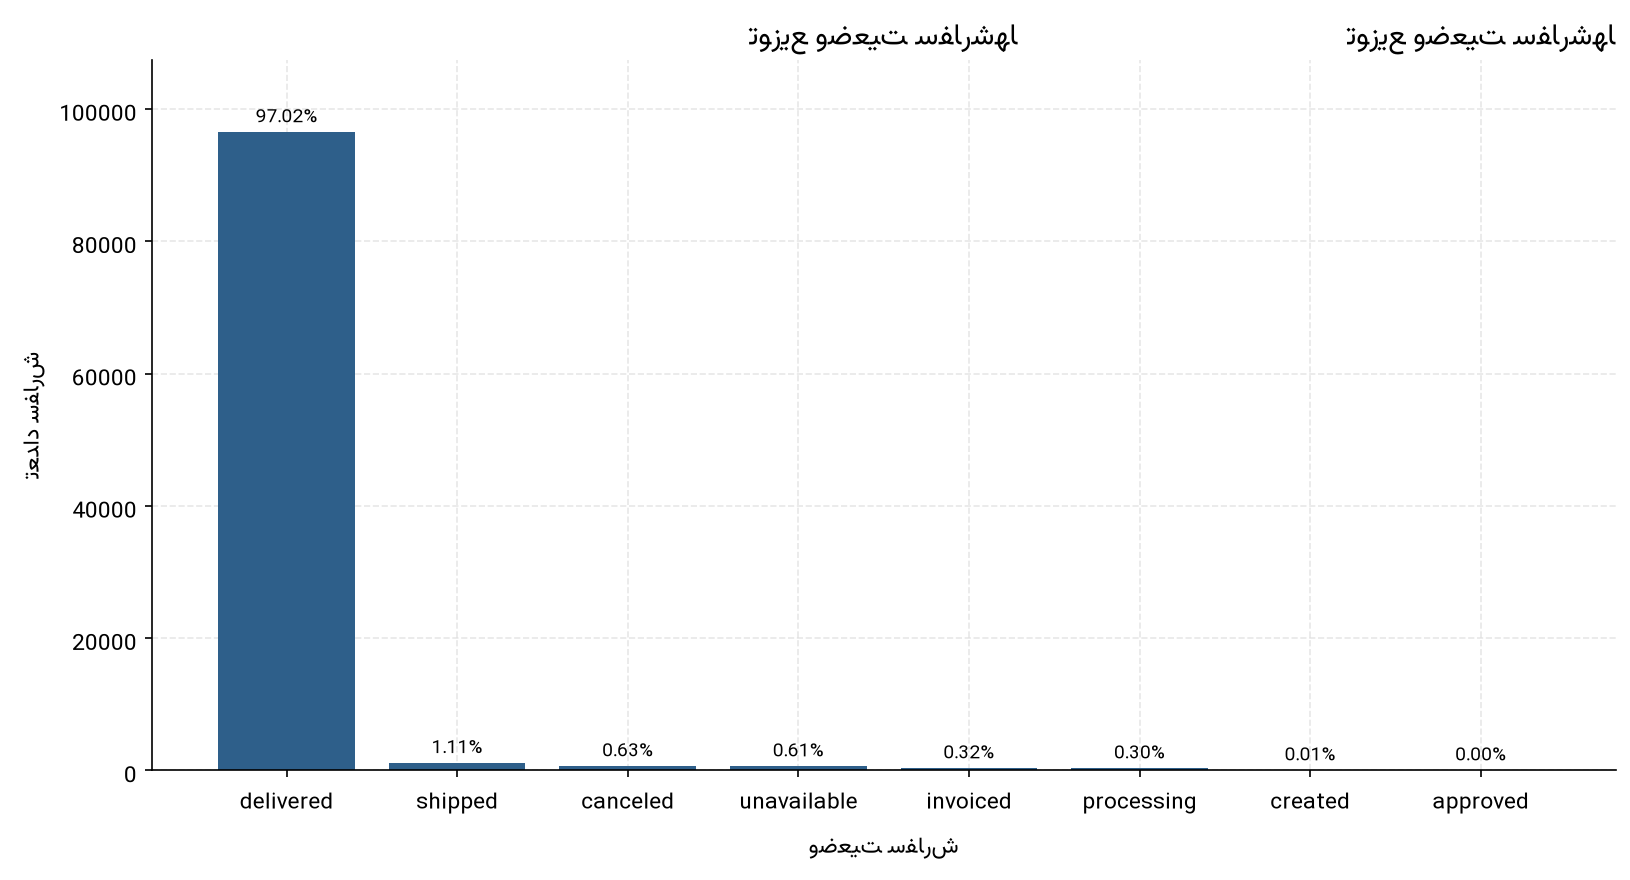

نمودار ۱ - توزیع سفارشها بر اساس وضعیت (n=99,441)


In [8]:
display(Image(filename=str(FIGURES_DIR / "fig_01_order_status.png"), width=920))
caption = FIGURES_DIR / "fig_01_order_status.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

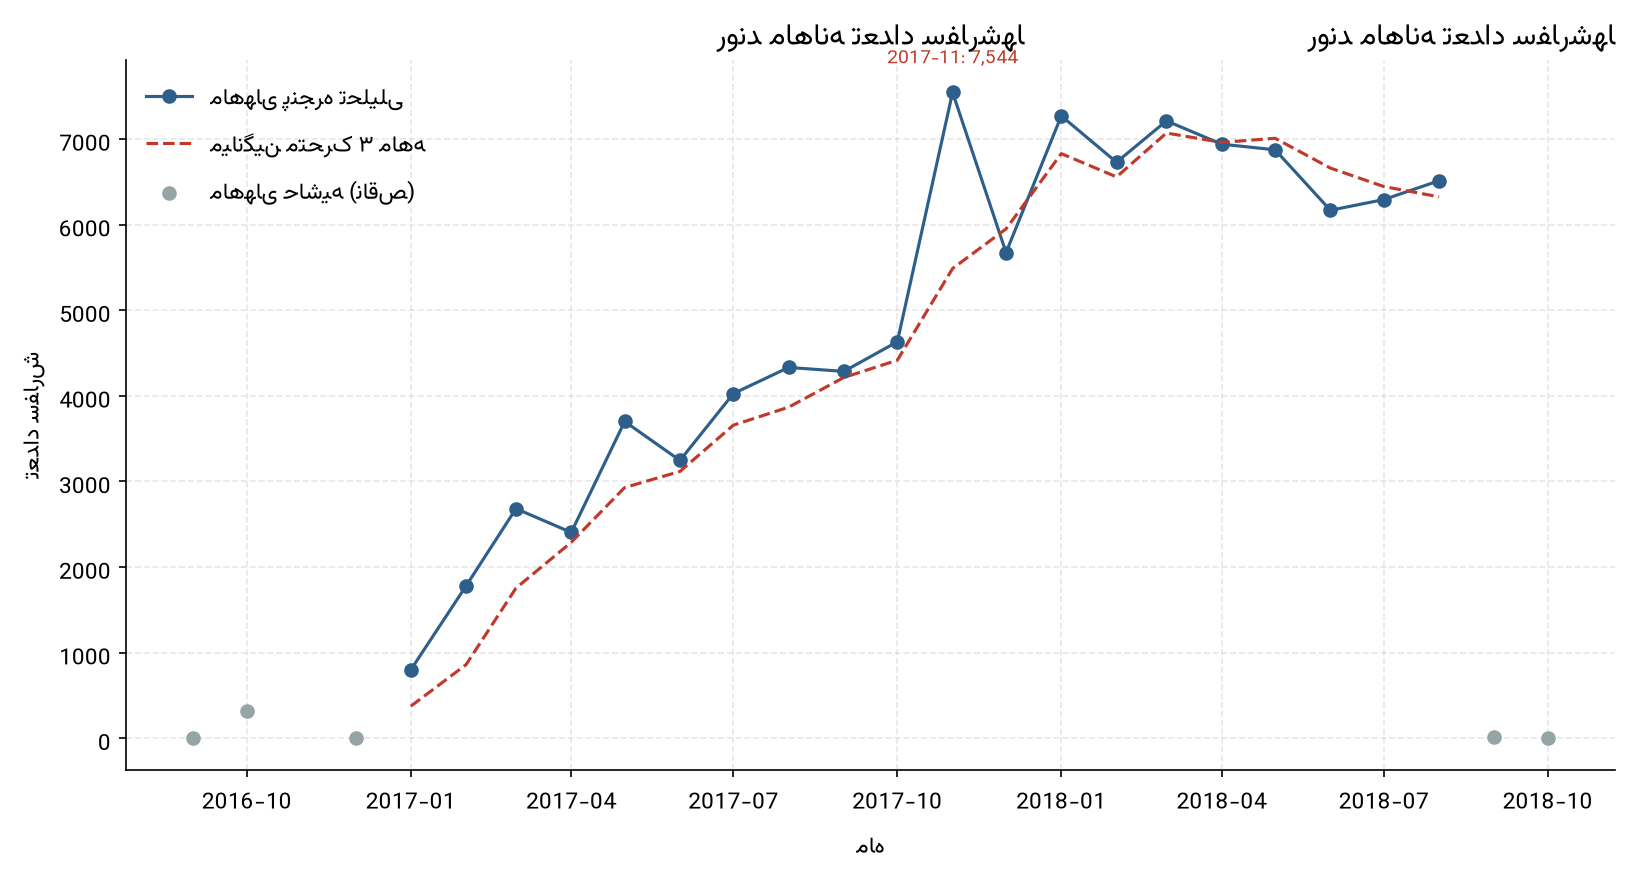

نمودار ۲ - روند ماهانه سفارشها؛ ماههای حاشیه از تحلیل روند کنار گذاشته شدهاند


In [9]:
display(Image(filename=str(FIGURES_DIR / "fig_02_monthly_orders.png"), width=920))
caption = FIGURES_DIR / "fig_02_monthly_orders.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

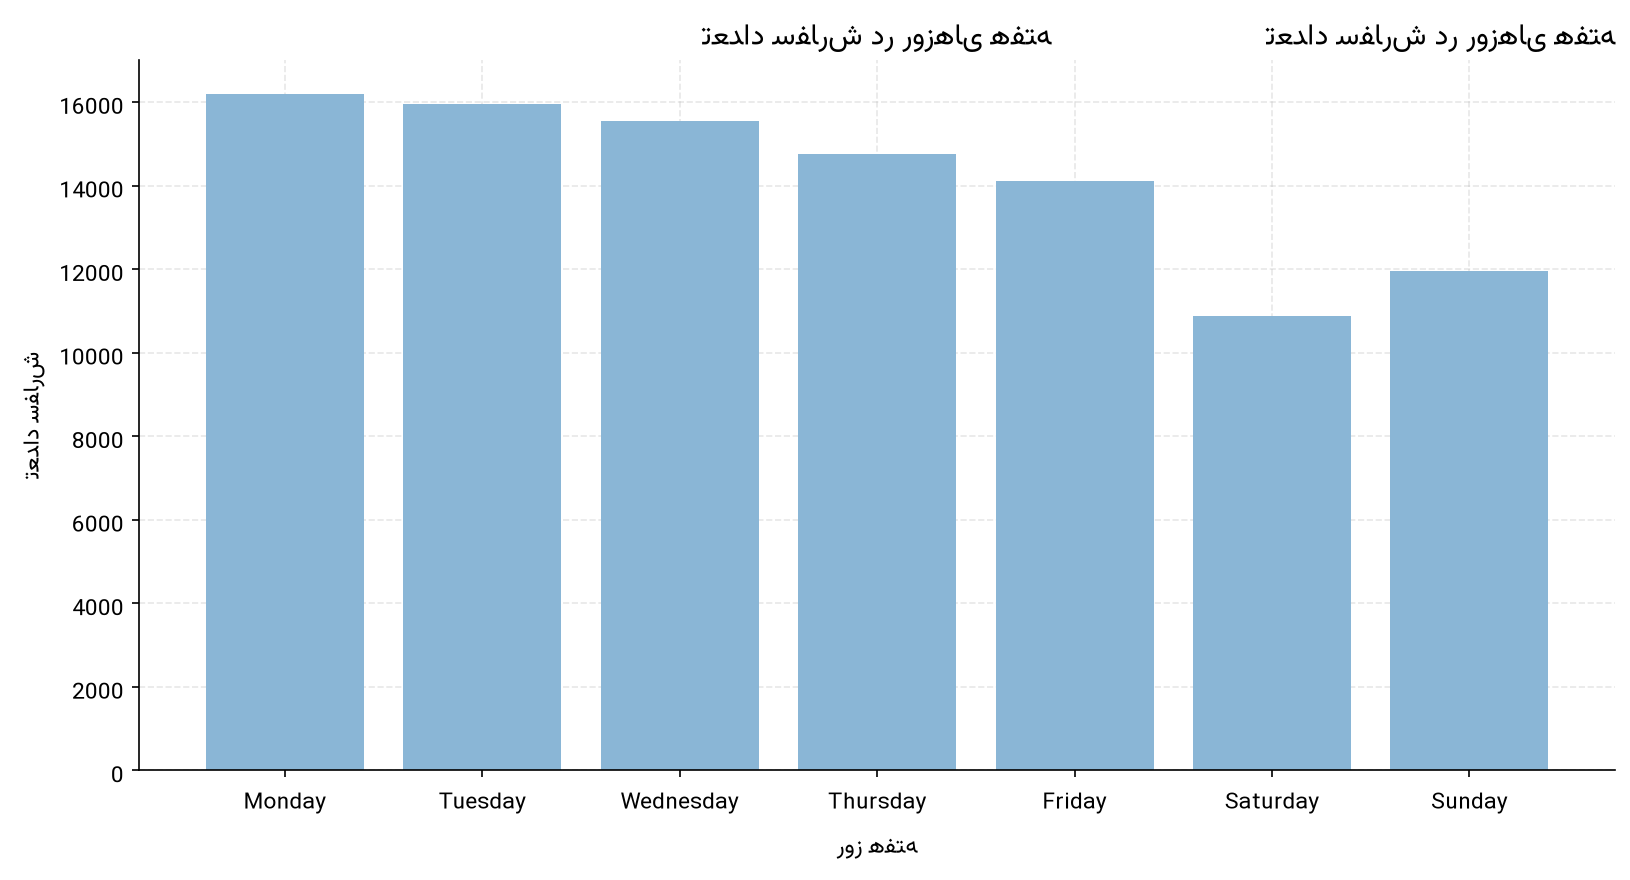

نمودار ۳ - توزیع سفارشها در روزهای هفته


In [10]:
display(Image(filename=str(FIGURES_DIR / "fig_03_weekday_orders.png"), width=920))
caption = FIGURES_DIR / "fig_03_weekday_orders.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

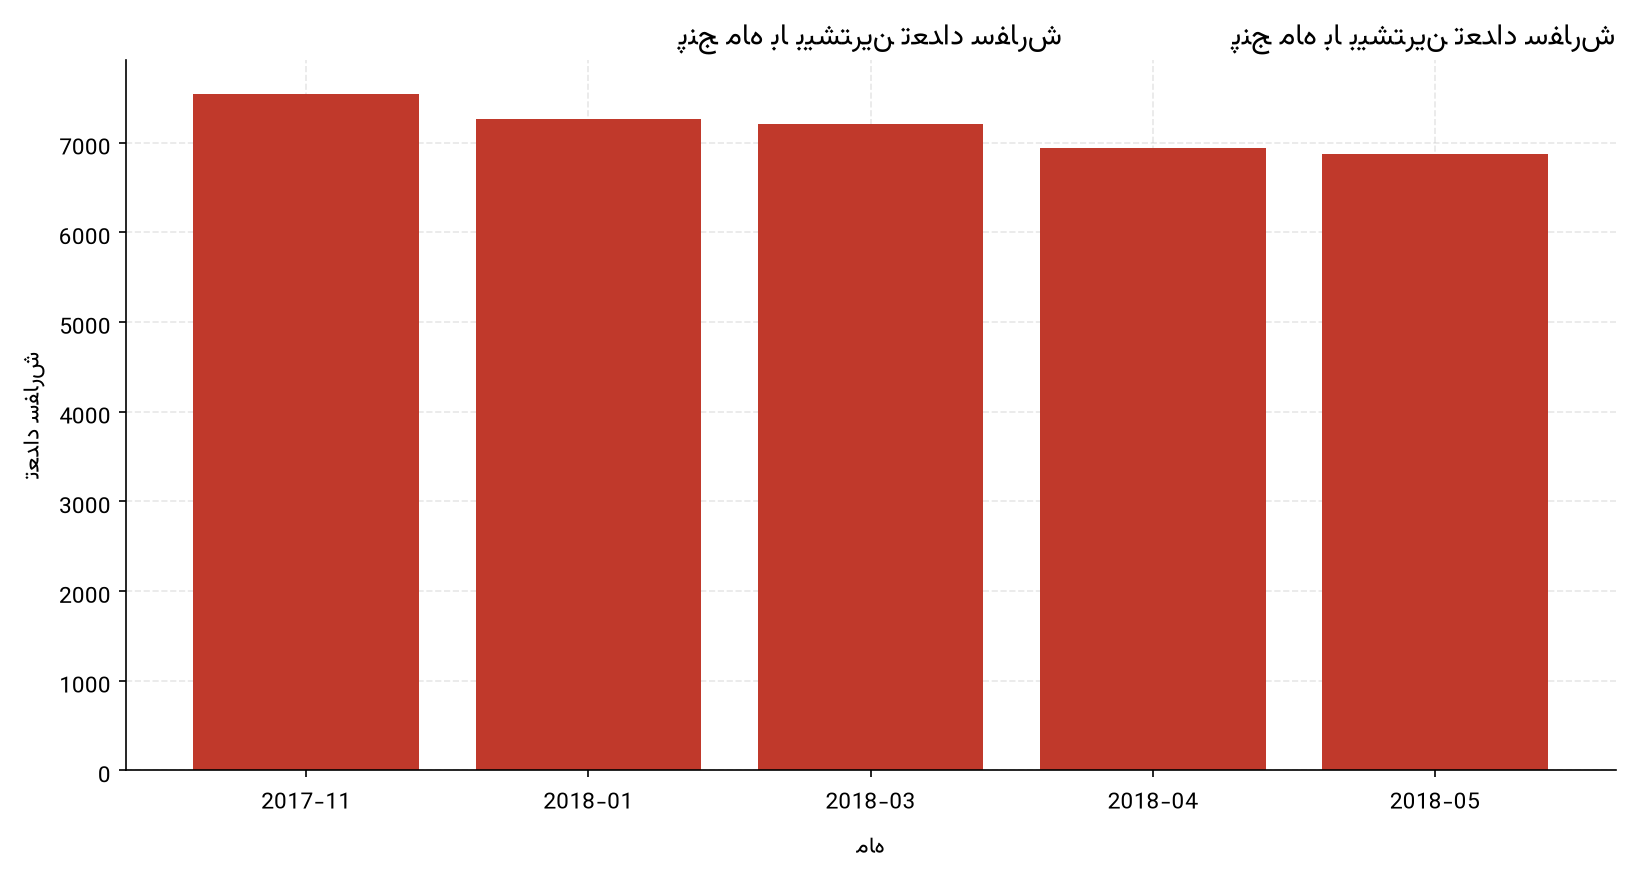

نمودار ۴ - پنج ماه پرترافیک


In [11]:
display(Image(filename=str(FIGURES_DIR / "fig_04_top_months.png"), width=920))
caption = FIGURES_DIR / "fig_04_top_months.txt"
print(caption.read_text(encoding="utf-8") if caption.exists() else "")

## ۸. یافته‌های واقعی

- ۹۹٬۴۴۱ سفارش ثبت شده که ۹۶٬۴۷۸ مورد (۹۷.۰۲ درصد) تحویل شده است.
- اوج فعالیت آبان ۲۰۱۷ با ۷٬۵۴۴ سفارش است؛ کمترین ماه پنجره تحلیلی ژانویه ۲۰۱۷ با ۸۰۰ سفارش.
- مقایسه هم‌دوره ژانویه تا اوت: ۲۲٬۹۶۸ سفارش در ۲۰۱۷ در برابر ۵۳٬۹۹۱ در ۲۰۱۸؛ رشد ۱۳۵.۰۷ درصد.
- دوشنبه پرترافیک‌ترین روز (۱۶٬۲۸۷ سفارش) و شنبه کم‌ترافیک‌ترین روز (۱۰٬۸۸۷ سفارش) است.
- هیچ الگوی فصلی روشنی دیده نمی‌شود؛ جهش آبان ۲۰۱۷ با کمپین‌های فروش همزمان است و در سال بعد تکرار نشده است.

## ۹. تفسیر کسب‌وکاری

کسب‌وکار از مرحله راه‌اندازی عبور کرده و به سطح فعالیت بزرگ‌تری رسیده است، اما رشد انفجاری ۲۰۱۷ در ۲۰۱۸ تکرار نشده و میانگین ماهانه در نیمه دوم سال ۲۰۱۸ کم‌تر از نیمه اول همان سال است. برنامه‌ریزی ظرفیت باید بر پایه سطح فعلی تقاضا انجام شود.

## ۱۰. محدودیت‌های تحلیل

مقایسه هم‌دوره، یک سال راه‌اندازی را با یک سال تثبیت‌شده می‌سنجد و درصد رشد را بیش از حد نشان می‌دهد. داده شامل شاخص‌های بازاریابی و هزینه کمپین نیست، بنابراین علت جهش آبان ۲۰۱۷ قابل تأیید نیست.

## ۱۱. نتیجه‌گیری

حجم فعالیت رشد کرده و تثبیت شده و الگوی فصلی پایدار ندارد؛ برنامه‌ریزی باید روی سطح فعلی سفارش‌ها و مدیریت اوج‌های کوتاه‌مدت متمرکز شود.